Universidad Torcuato Di Tella

Licenciatura en Tecnología Digital

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**

# **Trabajo Práctico — Ejercicio N°9: Reconstrucción tomográfica con regularización cuadrática**

Resolvemos todas las importaciones necesarias para el correcto funcionamiento del código.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [15]:
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

In [16]:
n = 8
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]
A7 = matriz_proyeccion(n, D7)[0]
A7 = np.array(A7)

X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

In [17]:
seed = 73
z = np.random.normal(loc=0.0, scale=1.0, size=119)

b7 = A7 @ x_fantoma
escala = np.sqrt(np.mean(b7**2))

ruido = 0.06 * escala * z
b_sigma = b7 + ruido

a) Implementar `matriz_diferencias(n)` siguiendo la construcción anterior. Verificar que cada fila contiene exactamente un $−1$ y un $1$, y comprobar que para $n = 8$ se obtiene $D \in \mathbb{R}^{112 \times 64}$.

In [18]:
def matriz_diferencias(n:int):
    '''
    Requiere: un entero n que representa la dimensión de la matriz sobre la cual se aplicará la matriz resultante.\n
    Devuelve: una matriz de diferencias D de tamaño 2n(n-1) x n².
    '''

    # Primero construimos el bloque Dh

    D = list()

    for i in range(n):
        for j in range(n-1):
            nueva_fila = np.zeros((n**2))
            nueva_fila[i*n + j] = -1
            nueva_fila[i*n + j+1] = 1
            D.append(nueva_fila)

    # Luego construimos el bloque Dv
    
    for j in range(n):
        for i in range(n-1):
            nueva_fila = np.zeros((n**2))
            nueva_fila[i*n + j] = -1
            nueva_fila[(i+1)*n + j] = 1
            D.append(nueva_fila)

    return np.array(D)

# Función para chequear que la suma de elementos da 0 para cada fila
def verificar_D(D:np.ndarray) -> bool:
    '''
    Requiere: una matriz D. \n
    Devuelve: `True` si hay exactamente un 1 y un -1 en cada fila. En caso contrario, devuelve `False`.
    '''

    for fila in D:
        if sum(fila) != 0: return False

    return True

Dimensión de D para n=8: (112, 64)
Es matriz de diferencias? -> True


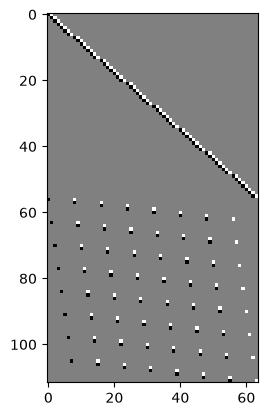

In [19]:
D8 = matriz_diferencias(n)
print("Dimensión de D para n=8:", np.shape(D8))
print("Es matriz de diferencias? ->", verificar_D(D8))

# Visualizamos la matriz D
plt.imshow(D8, cmap='gray')

b) Crear en Python el vector `x_constante = np.ones(n**2)`, que representa una imagen en la que todos los píxeles tienen valor $1$. Verificar que $Dx_{constante} = 0$ y explicar por qué todas las diferencias resultan nulas. Comparar este resultado con $∥Dx_{fantoma}∥$.

In [20]:
x_constante = np.ones(n**2)
Dx_constante = D8 @ x_constante
print("Dx_constante tiene dimensión", np.shape(Dx_constante))

print("Es Dx_constante nulo? ->", np.array_equal(Dx_constante, np.zeros((112))))
print("||Dx_constante|| =", np.linalg.norm(Dx_constante))

Dx_constante tiene dimensión (112,)
Es Dx_constante nulo? -> True
||Dx_constante|| = 0.0


En la imagen $x_{constante}$, todos los píxeles tienen el mismo valor de atenuación. Esto implica que, para cualquier par de píxeles, no hay ninguna diferencia entre ellos. Particularmente, para nuestro caso nos interesa saber que $x_{i,j} = x_{i,j+1}$ y $x_{i,j} = x_{i+1,j}$. De esta manera, naturalmente, todas las diferencias computadas mediante el producto $Dx_{constante}$ dan $0$.

Contrastando con $Dx_{fantoma}$:

In [21]:
Dx_fantoma = D8 @ x_fantoma

print("Dx_fantoma tiene dimensión", np.shape(Dx_fantoma))
print("Es Dx_fantoma nulo? ->", np.array_equal(Dx_fantoma, np.zeros((112))))
print("||Dx_fantoma|| =", np.linalg.norm(Dx_fantoma))

Dx_fantoma tiene dimensión (112,)
Es Dx_fantoma nulo? -> False
||Dx_fantoma|| = 2.7055498516937364


Analicemos las diferencias entre pares de forma más visual.

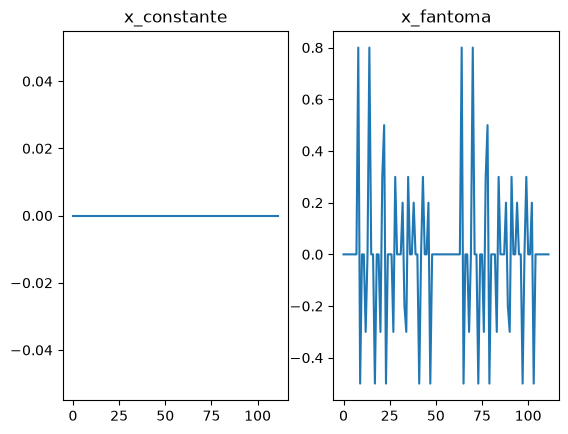

In [22]:
plt.subplot(1,2,1)
plt.title("x_constante")
plt.plot(Dx_constante)

plt.subplot(1,2,2)
plt.title("x_fantoma")
plt.plot(Dx_fantoma)

En el caso de la tomografía simulada, no todos los pares de píxeles horizontales y verticales tienen la misma atenuación. Entonces, resulta natural que no todas las diferencias devuelvan $0$.

c) Interpretar las expresiones provistas. Explicar qué mide cada término de $J_{\sigma,\lambda}$, qué representa $∥D_x∥$ y cuál es el papel de $\lambda$.

$$J_{\sigma,\lambda}(x)=\frac{1}{2}(||A_7x-b_\sigma||^2 + \lambda||Dx||^2)$$

$J_{\sigma,\lambda}(x)$ es una función objetivo a minimizar a través de métodos iterativos (tales como el método del gradiente y el método de Newton) para obtener una reconstrucción $\hat{x}_\sigma$ lo más fiable posible. El primer término $||A_7x-b_\sigma||$ mide la distancia entre la mejor solución hallada hasta el momento y las mediciones, tal como se hacía en el ejercicio anterior. El segundo término, además, penaliza de acuerdo a la norma del vector de diferencias $||Dx||$. Esto implica que, en los términos de esta nueva función, cuanto más pronunciadas sean las diferencias entre los diferentes pares horizontales y verticales de píxeles, peor será la solución hallada. El coeficiente $\lambda$ se encarga de regular la intensidad de la penalización: a mayor $\lambda$, mayor es el costo numérico de las diferencias.

d) Reutilizar las mediciones limpias $b_7 = A_7 x_{fantoma}$ y el vector aleatorio $z$ del ejercicio sobre ruido.
Generar mediciones para $\sigma \in \{0, 0.10, 0.20\}$ mediante:

`escala = np.sqrt(np.mean(b7**2))`

`b_sigma = b7 + sigma * escala * z`

Utilizar el mismo vector $z$ en los tres casos, de modo que sólo cambie la intensidad del ruido.

In [23]:
# escala y z ya fueron importados de forma preliminar más arriba en el notebook

b_sigma_00 = b7   # (0 * escala * z) =  vector 0
b_sigma_01 = b7 + (0.1 * escala * z)
b_sigma_02 = b7 + (0.2 * escala * z)

e) Adaptar gradiente descendiente para minimizar $J_{\sigma,\lambda}$ para cada combinación de $\sigma \in \{0, 0.10, 0.20\}$ y $\lambda \in \{0, 0.1, 0.3, 1\}$. Comenzar siempre con $x_0 = 0$.

In [ ]:
# Definimos la función objetivo
def J(x:np.array, b:np.array, D:np.ndarray, lmbd:float):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.

    Devuelve: un número flotante que resulta de evaluar la función objetivo con los parámetros dados.
    '''
    t1 = np.linalg.norm( (A7 @ x) - b )
    t2 = np.linalg.norm( D @ x )
    return 0.5 * (t1**2 + lmbd * (t2**2))

# Definimos el gradiente de la función objetivo
def grad_J(x:np.array, b:np.array, D:np.ndarray, lmbd:float):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.

    Devuelve: un número flotante que resulta de evaluar el gradiente de la función objetivo.
    '''
    t1 = A7.transpose() @ (A7@x -b)
    t2 = lmbd * (D.transpose() @ D @ x)
    return t1 + t2

In [ ]:
# Adaptación del método del gradiente
def gradiente_descendente_v2(x_0, bs, D, lmbd, alpha = 0.01, tolerancia = 0.0001, max_iter = 1000, verbose=False):
    '''
    Requiere:

    - Un vector de solución parcial `x`.
    - Un vector de mediciones `b` sobre el cual comparar.
    - Una matriz `D` de diferencias.
    - Un float `lmbd` para regular la penalización por diferencias.
    - (Opcional) Un float `alpha` que representa la tasa de aprendizaje (0.01 por defecto).
    - (Opcional) Un float `tolerancia` que funciona como criterio para seguir iterando (0.01 por defecto).
    - (Opcional) Un entero `max_iter` como cota superior de las iteraciones del método (1000 por defecto).
    - (Opcional) Un bool `verbose` para imprimir los resultados de las iteraciones (0.01 por defecto).

    Devuelve: un objeto `tuple` con un vector de la mejor solución hallada, un vector de costos y un vector con las normas del gradiente.
    '''

    x_t   = x_0

    cost_log = list()
    grad_norm_log = list()

    iter  = 0

    while iter <= max_iter:
        
        x_tsig = x_t - alpha * grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)

        cost_log.append( J(x=x_t, b=bs, D=D, lmbd=lmbd) )
        grad_norm_log.append(np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))
        if verbose: print("Iteración", iter, "-> Mínimo hallado hasta ahora: ", J(x=x_t, b=bs, D=D, lmbd=lmbd), "-- Norma del gradiente: ", np.linalg.norm(grad_J(x=x_t, b=bs, D=D, lmbd=lmbd)))

        if abs( J(x=x_tsig, b=bs, D=D, lmbd=lmbd) - J(x=x_t, b=bs, D=D, lmbd=lmbd)) < tolerancia:
          break

        x_t = x_tsig
        iter = iter + 1

    return np.array(x_tsig), cost_log, grad_norm_log

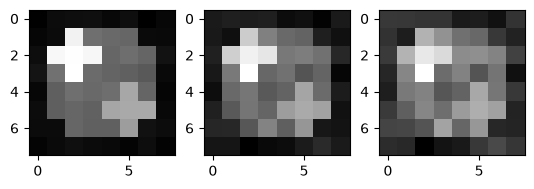

In [29]:
res_b_sigma_00 = {
    "0" : 0,
    "0.1" : 0,
    "0.3" : 0,
    "1" : 0
}

res_b_sigma_01 = {
    "0" : 0,
    "0.1" : 0,
    "0.3" : 0,
    "1" : 0
}

res_b_sigma_02 = {
    "0" : 0,
    "0.1" : 0,
    "0.3" : 0,
    "1" : 0
}

for l in [0, 0.1, 0.3, 1]:
    res_b_sigma_00[str(l)] = gradiente_descendente_v2(np.zeros((64)), bs=b_sigma_00, D=D8, lmbd=l)
    res_b_sigma_01[str(l)] = gradiente_descendente_v2(np.zeros((64)), bs=b_sigma_01, D=D8, lmbd=l)
    res_b_sigma_02[str(l)] = gradiente_descendente_v2(np.zeros((64)), bs=b_sigma_02, D=D8, lmbd=l)

plt.subplot(1,3,1)
plt.imshow(res_b_sigma_00["0.1"][0].reshape(8,8), cmap='gray')

plt.subplot(1,3,2)
plt.imshow(res_b_sigma_01["0.1"][0].reshape(8,8), cmap='gray')

plt.subplot(1,3,3)
plt.imshow(res_b_sigma_02["0.1"][0].reshape(8,8), cmap='gray')
